# 08 Transformer输入层、掩码与多头注意力实现

本篇对应网盘资料 `03-视频/day08`，已核对当天 **16个视频文件名**，并在线阅读《08-Tranformer架构和实现.pdf》第21—50页（原文件名如此）。视频未逐节转录，课程原始代码未读取；下面的示例依据课件所讲接口独立编写，并实际执行验证。

07介绍了Transformer的整体架构。本篇沿着 **token ID → 词嵌入 → 位置编码 → 掩码与注意力 → 多头注意力 → 前馈网络** 的路线实现基础组件。残差、LayerNorm以及完整编码器/解码器的组装留待后续课程。

延续前面的笔记格式：所有单元均为Markdown；把各段Python代码**按出现顺序复制到同一个Python会话**运行。示例使用CPU和小尺寸张量，不需要下载语料，也不训练完整翻译模型。图示全部嵌入本Notebook的attachments，复制笔记时不需要携带图片目录。

## 1. 学习路线与张量记号

多头注意力里最容易混淆的是“句子长度”和“特征维度”。先把每一维的含义写出来，再做乘法、转置和拆头。

| 记号 | 含义 | 本篇主要示例 |
| --- | --- | --- |
| B | batch中的句子数 | 3 |
| Lq / Lk | query / key序列长度 | 4 / 5；交叉注意力可不同 |
| D或d_model | 模型特征维度 | 16 |
| H | 注意力头数 | 4 |
| d_k | 每个头的query/key维度 | D/H=4 |
| d_ff | 前馈层中间维度 | 32 |

输入ID形状是 `(B,L)`，embedding后是 `(B,L,D)`；多头注意力权重是 `(B,H,Lq,Lk)`。注意力输出长度由**query**决定，所以cross-attention返回 `(B,Lq,D)`，不会自动变成源句长度。

课程测试常用 `B=2,L=4,D=512,H=8`，对应每头64维。本篇使用小尺寸便于逐项检查，并刻意让 `B≠H`，帮助暴露把batch轴误当成head轴的掩码错误。

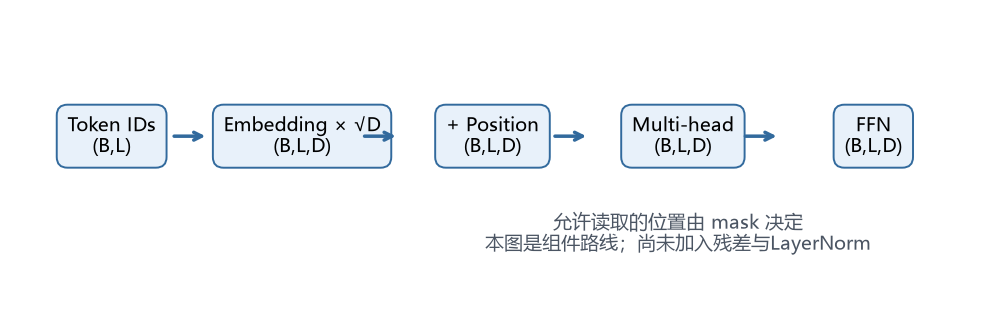

## 2. 运行环境与可复现设置

依赖为 `torch、numpy、matplotlib`，安装方式为 `pip install torch numpy matplotlib`。本Notebook本身不执行Markdown里的代码；以下设置供复制运行时使用。固定随机种子有助于重复本篇CPU实测，换版本或设备时小数末位仍可能变化。

```python
import math, platform
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(2026)
np.random.seed(2026)
torch.set_num_threads(1)
torch.set_printoptions(precision=4, sci_mode=False)
plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False
B, D, H, PAD = 3, 16, 4, 0
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| NumPy:', np.__version__)
print('device: cpu | D/H:', D // H)
```

本段实测输出：

```text
Python: 3.12.13
PyTorch: 2.14.1+cpu | NumPy: 2.5.4
device: cpu | D/H: 4
```

## 3. Embeddings：把整数ID变成可训练向量

`nn.Embedding(V,D)`保存一个 `(V,D)` 的可训练查找表。输入是整数ID，而非one-hot或已有词向量。词表大小为V时，合法ID为 `0≤id<V`；课件第30页的1000词表不能接收ID=1001。

原始Transformer采用 `Embedding(ids) × √D`，以调整词嵌入与固定位置编码的相对尺度。这是架构中的缩放选择，不等于归一化，也不保证两者在任何初始化下方差完全相同。

```python
class Embeddings(nn.Module):
    def __init__(self, vocab_size, d_model, padding_idx=0):
        super().__init__()
        self.d_model = d_model
        self.lut = nn.Embedding(vocab_size, d_model,
                                padding_idx=padding_idx)

    def forward(self, ids):
        return self.lut(ids) * math.sqrt(self.d_model)

ids = torch.tensor([[1, 4, 5, 2],
                    [1, 6, 2, 0],
                    [1, 2, 0, 0]], dtype=torch.long)
embedding = Embeddings(20, D, PAD)
embedded = embedding(ids)
assert embedded.shape == (B, 4, D)
assert torch.all(embedded[ids == PAD] == 0)
torch.testing.assert_close(embedded, embedding.lut(ids) * math.sqrt(D))
print('ID → embedding:', tuple(ids.shape), '→', tuple(embedded.shape))
print('PAD embedding为0:', bool((embedded[ids == PAD] == 0).all()))
```

`padding_idx`使本示例的PAD行初始化为0且不接收embedding梯度；后续位置编码、线性层bias仍可能让PAD位置的表示非零。**PAD embedding为0不能代替attention mask或loss mask。**

本段实测输出：

```text
ID → embedding: (3, 4) → (3, 4, 16)
PAD embedding为0: True
```

## 4. 正弦位置编码：让模型区分顺序

没有位置信息的双向self-attention对位置置换具有等变性：重排输入，输出随之重排。它可以比较token内容，却不能仅靠这层判断“你欠我”和“我欠你”的顺序区别。位置编码在同一token的不同位置上加入不同向量。

$$PE(pos,2i)=\sin\left(pos/10000^{2i/D}\right)$$
$$PE(pos,2i+1)=\cos\left(pos/10000^{2i/D}\right)$$

`pos`是从0开始的位置；`i`是正弦/余弦对的编号，实际特征索引是 `2i` 与 `2i+1`。低索引维度变化快，高索引维度变化慢。正弦编码是固定值，模型通过后续可学习参数使用它；它不直接等于“语义”，也不自动保证超长序列上的泛化。

这里将编码**相加**到词向量，形状仍为 `(B,L,D)`；若改为拼接，则会改变维度与后续层接口。可学习绝对位置embedding、相对位置方法、RoPE等是其他位置方案，不能与本篇的正弦相加实现混为一谈。

## 5. PositionalEncoding实现：buffer、广播与offset

`position`形状 `(max_len,1)`，`div_term`形状 `(ceil(D/2),)`；广播乘法得到各位置、各频率的相位。`pe`注册为buffer：随模型迁移设备，默认进入 `state_dict()`，但不会作为参数交给优化器。现在直接使用Tensor即可，无需旧版 `Variable`。

```python
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=128):
        super().__init__()
        if d_model <= 0 or max_len <= 0:
            raise ValueError('d_model/max_len必须为正')
        self.dropout = nn.Dropout(dropout)
        position = torch.arange(max_len, dtype=torch.float32)[:, None]
        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                             * (-math.log(10000.0) / d_model))
        angles = position * div_term
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(angles)
        # 奇数D时，余弦列比正弦列少一列。
        pe[:, 1::2] = torch.cos(angles[:, :pe[:, 1::2].shape[1]])
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x, offset=0):
        if x.ndim != 3 or x.shape[-1] != self.pe.shape[-1]:
            raise ValueError('x必须是(B,L,D)，且D与位置编码一致')
        if not x.is_floating_point():
            raise TypeError('位置编码输入必须是浮点特征')
        if not isinstance(offset, int) or offset < 0:
            raise ValueError('offset必须是非负整数')
        end = offset + x.shape[1]
        if end > self.pe.shape[1]:
            raise ValueError('序列超出max_len')
        position_features = self.pe[:, offset:end].to(x)
        return self.dropout(x + position_features)

position = PositionalEncoding(D, dropout=0.1, max_len=64).eval()
x = position(embedded)
assert x.shape == embedded.shape
assert 'pe' in position.state_dict()
assert 'pe' not in dict(position.named_parameters())
torch.testing.assert_close(position.pe[0, 0, 0::2], torch.zeros(D//2))
torch.testing.assert_close(position.pe[0, 0, 1::2], torch.ones(D//2))
# 分块时必须使用全局位置；关闭dropout后可比较。
torch.testing.assert_close(x[:, 2:], position(embedded[:, 2:], offset=2))
odd = PositionalEncoding(7, dropout=0, max_len=10)
assert odd(torch.zeros(2, 3, 7)).shape == (2, 3, 7)
print('位置编码后:', tuple(x.shape))
print('buffer保存、非参数、offset一致、奇数D兼容：通过')
```

`offset`演示全局位置切片，尚未实现KV cache。正式使用仍应将模型与输入放在同一设备；这里 `.to(x)`保持位置特征的device/dtype与输入一致。位置编码相加后PAD位置通常非零，所以后面的key padding mask仍然必需。

本段实测输出：

```text
位置编码后: (3, 4, 16)
buffer保存、非参数、offset一致、奇数D兼容：通过
```

## 6. 位置编码可视化

热力图的行是位置，列是特征索引。右图只选几个维度，展示同一位置在不同频率上的编码；这是固定公式的值，不是训练后Attention权重。

```python
pe_plot = PositionalEncoding(32, dropout=0, max_len=64).pe[0].numpy()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout='constrained')
im = axes[0].imshow(pe_plot, aspect='auto', cmap='coolwarm',
                    vmin=-1, vmax=1, origin='upper')
axes[0].set(xlabel='特征索引', ylabel='位置pos', title='正弦位置编码')
fig.colorbar(im, ax=axes[0], shrink=0.85)
for dim in [0, 1, 4, 5]:
    axes[1].plot(np.arange(64), pe_plot[:, dim], label=f'dim {dim}')
axes[1].set(xlabel='位置pos', ylabel='编码值', title='不同频率的sin/cos')
axes[1].legend(ncol=2, fontsize=9)
axes[1].grid(alpha=0.2)
plt.show()
```

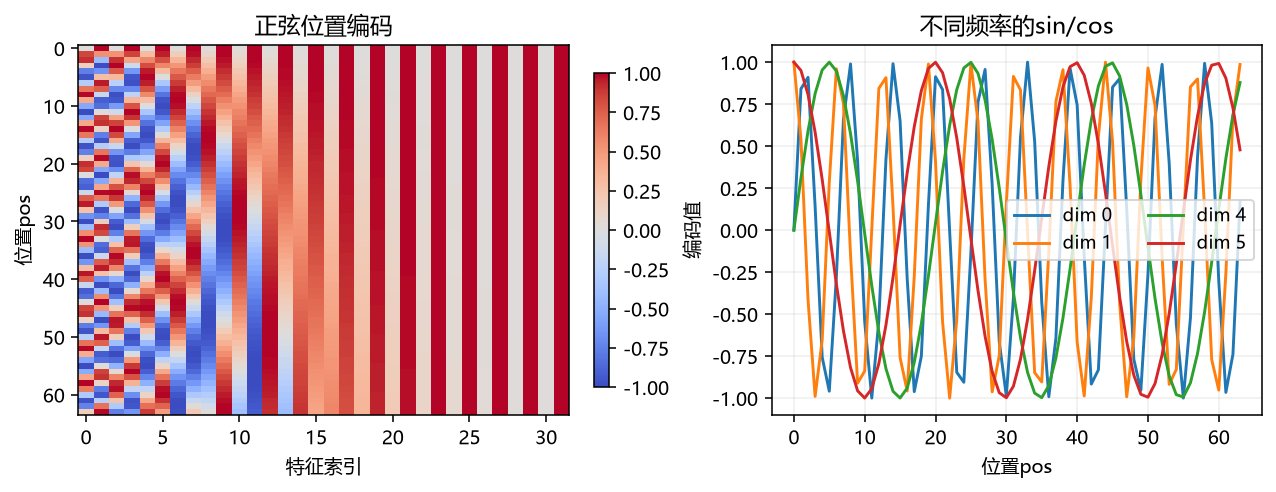

## 7. 上下三角矩阵与causal mask

`triu`保留上三角，`tril`保留下三角；判断三角矩阵应看哪些区域保留、哪些区域清零，而不是把“0的形状”当成定义。`diagonal=1`的上三角恰好包含未来位置；取反后就是**包含对角线**的下三角可见区域。

**本篇统一使用allow布尔掩码：True=允许读取，False=屏蔽。** 行表示query位置，列表示key位置。

```python
def causal_allow(length, device=None):
    if length <= 0:
        raise ValueError('length必须为正')
    return torch.ones(length, length, dtype=torch.bool,
                       device=device).tril()[None, None]

future_block = torch.ones(4, 4, dtype=torch.bool).triu(diagonal=1)
causal = causal_allow(4)
assert torch.equal(causal[0, 0], ~future_block)
assert causal.shape == (1, 1, 4, 4)
print('未来区域，上三角1=屏蔽：\n', future_block.int())
print('本篇allow，下三角1=可见：\n', causal[0, 0].int())
```

decoder输入已经右移时，例如输入 `[SOS, je, suis]`、标签 `[je, suis, EOS]`，第1行可以读取SOS，第2行可以读取SOS和je。对角线是**当前输入token**，不是当前位置要预测的标签，所以不应再遮住对角线。右移输入与屏蔽未来必须同时满足；仅加causal mask仍无法补救未右移的标签泄漏。

本段实测输出：

```text
未来区域，上三角1=屏蔽：
 tensor([[0, 1, 1, 1],
        [0, 0, 1, 1],
        [0, 0, 0, 1],
        [0, 0, 0, 0]], dtype=torch.int32)
本篇allow，下三角1=可见：
 tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)
```

## 8. Padding mask与广播：别把batch当作head

多头分数的shape为 `(B,H,Lq,Lk)`。只屏蔽key padding时，allow用 `(B,1,1,Lk)`；causal用 `(1,1,L,L)`。逻辑与后得到 `(B,1,L,L)`，在head轴自动广播。输入 `(B,L,L)`不能直接当作通用多头mask：右对齐广播时，它的B轴可能对齐H轴。

```python
key_allow = (ids != PAD)[:, None, None, :]  # (3,1,1,4)
self_allow = key_allow & causal_allow(ids.shape[1])
assert self_allow.shape == (B, 1, 4, 4)
assert self_allow.any(dim=-1).all()
print('key padding allow:', tuple(key_allow.shape))
print('组合allow:', tuple(self_allow.shape))
print('第2句组合mask：\n', self_allow[1, 0].int())

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3), layout='constrained')
for ax, matrix, title in zip(axes,
        [causal[0, 0], self_allow[1, 0]],
        ['causal：允许当前位置及过去', 'causal + key padding：第2句']):
    ax.imshow(matrix.int(), cmap='Blues', vmin=0, vmax=1)
    for row in range(4):
        for col in range(4):
            ax.text(col, row, str(int(matrix[row, col])), ha='center',
                    va='center', color='white' if matrix[row, col] else '#263445')
    ax.set(xticks=range(4), yticks=range(4), xlabel='key位置（列）',
           ylabel='query位置（行）', title=title)
plt.show()
```

图中1=可见，0=屏蔽。第2句最后一列是PAD，整列不可见；最后一个query也是PAD，但仍可读前面的有效key。**只屏蔽key不会把PAD query的输出自动变成0。** 通常用 `ignore_index=PAD`排除这些位置的loss，或在需要时将query输出显式清零；不要为此把每个PAD query整行都填成−∞，那会引出全屏蔽行问题。全PAD样本在本篇会被拒绝。

本段实测输出：

```text
key padding allow: (3, 1, 1, 4)
组合allow: (3, 1, 4, 4)
第2句组合mask：
 tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 0]], dtype=torch.int32)
```

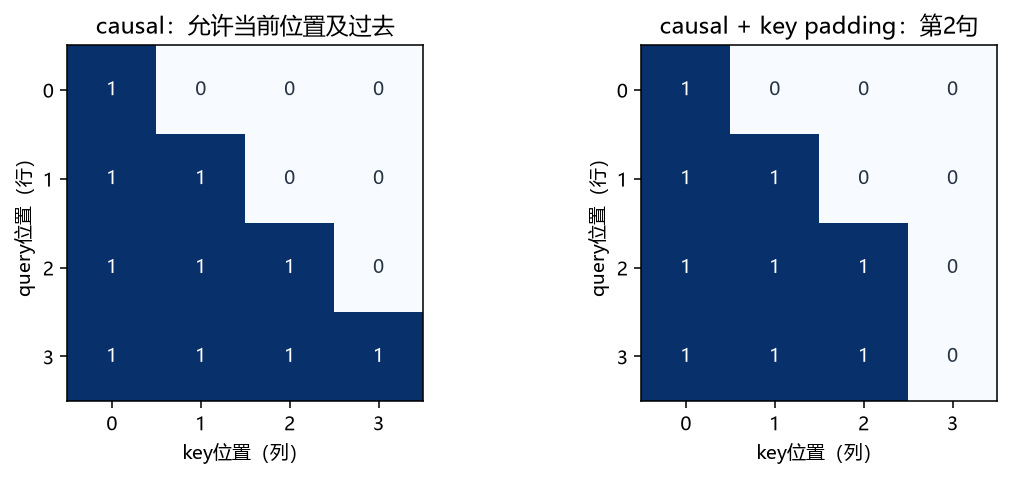

## 9. 缩放点积注意力：score、weight、context各是什么

$$S=\frac{QK^T}{\sqrt{d_k}},\qquad
A=\operatorname{softmax}(S+M),\qquad C=AV$$

允许位置的M为0，屏蔽位置的M为−∞。`S`是未归一化分数，`A`才是注意力概率，`C`是加权后的特征。对于 `(B,H,Lq,d_k)` 的Q和 `(B,H,Lk,d_k)` 的K，转置K的最后两轴后，矩阵乘法返回 `(B,H,Lq,Lk)`。

若Q/K各维近似独立、均值0、方差1，点积方差随d_k增长；除以√d_k能缓解softmax过尖与梯度变小。这是常见的尺度解释，不等于对Q/K做单位长度归一化。

操作顺序是 **点积 → 缩放 → masked_fill → softmax → 可选dropout → 乘V**。必须在softmax前屏蔽；softmax后简单乘0会破坏行和，且需要另行重新归一化。`torch.matmul`可处理多头4维张量，`torch.bmm`只接收3维batch矩阵。

## 10. masked_fill与全屏蔽行：形状正确还不够

全行都填 `−1e9`，softmax会得到均匀分布，而非全0；全行都填 `−∞`，常规softmax会得到NaN。本篇采取明确策略：**每行至少有一个可见key，否则报错**，让上游检查样本与mask。若业务必须支持空行，需要单独定义“输出0”等策略及梯度行为。

```python
def scaled_attention(q, k, v, allow=None, dropout=None):
    if q.ndim not in (3, 4) or k.ndim != q.ndim or v.ndim != q.ndim:
        raise ValueError('Q/K/V必须同为3维或4维')
    if not (q.shape[:-2] == k.shape[:-2] == v.shape[:-2]):
        raise ValueError('Q/K/V前导维度必须一致')
    if q.shape[-1] != k.shape[-1] or k.shape[-2] != v.shape[-2]:
        raise ValueError('Q/K维度及K/V长度必须匹配')
    if q.shape[-1] <= 0 or k.shape[-2] <= 0:
        raise ValueError('特征维度与key长度必须为正')
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if allow is not None:
        if allow.dtype != torch.bool or allow.device != scores.device:
            raise TypeError('allow必须是同设备的布尔Tensor')
        visible = torch.broadcast_to(allow, scores.shape)
        if not visible.any(dim=-1).all().item():
            raise ValueError('attention存在全屏蔽行')
        scores = scores.masked_fill(~visible, float('-inf'))
    weights = scores.softmax(dim=-1)
    used_weights = weights if dropout is None else dropout(weights)
    return used_weights @ v, weights, used_weights

print('全−1e9行softmax:', torch.full((1, 4), -1e9).softmax(-1))
print('全−∞行含NaN:', bool(torch.isnan(
      torch.full((1, 4), float('-inf')).softmax(-1)).any()))
try:
    scaled_attention(torch.zeros(1, 2, 2), torch.zeros(1, 2, 2),
                     torch.zeros(1, 2, 2), torch.zeros(1, 2, 2, dtype=torch.bool))
except ValueError as err:
    print('本篇策略:', err)
else:
    raise AssertionError('全屏蔽行应被拒绝')
```

`weights`保留softmax后的概率；`used_weights`是实际乘V的矩阵。训练时注意力dropout会把部分概率置零，并将保留值除以 `1-p`，所以used_weights逐行不一定和为1。本函数适合教学检查；逐次 `.item()`的验证会在GPU上引入同步，生产实现应考虑高效校验与融合算子。

本段实测输出：

```text
全−1e9行softmax: tensor([[0.2500, 0.2500, 0.2500, 0.2500]])
全−∞行含NaN: True
本篇策略: attention存在全屏蔽行
```

## 11. 二维手算样例：一行对应一个query

设Q和K均为二维单位基，V分别为 `[10,0]` 与 `[0,20]`。第2个query的分数为 `[0,1/√2]`，概率约为 `[0.3302,0.6698]`，context约为 `[3.3024,13.3952]`。第1行因causal mask只允许第1列，输出恰好等于第1个V。

```python
q_toy = torch.eye(2)[None]
k_toy = q_toy.clone()
v_toy = torch.tensor([[[10., 0.], [0., 20.]]])
allow_toy = torch.ones(2, 2, dtype=torch.bool).tril()[None]
context_toy, weights_toy, used_toy = scaled_attention(
    q_toy, k_toy, v_toy, allow_toy)
torch.testing.assert_close(weights_toy.sum(-1), torch.ones(1, 2))
assert weights_toy[0, 0, 1] == 0
torch.testing.assert_close(context_toy[0, 0], v_toy[0, 0])
expected_p = torch.softmax(torch.tensor([0., 1/math.sqrt(2)]), -1)
torch.testing.assert_close(weights_toy[0, 1], expected_p)
print('注意力概率：\n', weights_toy[0])
print('加权特征context：\n', context_toy[0])

drop = nn.Dropout(0.5).train()
drop_context, raw_w, dropped_w = scaled_attention(
    q_toy, k_toy, v_toy, allow_toy, dropout=drop)
assert ((dropped_w == 0) | torch.isclose(dropped_w, raw_w * 2)).all()
torch.testing.assert_close(drop_context, dropped_w @ v_toy)
torch.testing.assert_close(raw_w.sum(-1), torch.ones(1, 2))
drop.eval()
_, eval_w, eval_used = scaled_attention(q_toy, k_toy, v_toy,
                                       allow_toy, dropout=drop)
torch.testing.assert_close(eval_w, eval_used)
print('dropout训练缩放与eval关闭：通过')
```

本段实测输出：

```text
注意力概率：
 tensor([[1.0000, 0.0000],
        [0.3302, 0.6698]])
加权特征context：
 tensor([[10.0000,  0.0000],
        [ 3.3024, 13.3952]])
dropout训练缩放与eval关闭：通过
```

## 12. 多头注意力：先学投影，再拆头

$$head_h=Attention(X_qW_h^Q,X_kW_h^K,X_vW_h^V)$$
$$MultiHead=Concat(head_1,\ldots,head_H)W^O$$

多头不是直接把原始embedding切几块就结束。Q/K/V先经各自可学习投影，再拆分head轴，最后拼回并做输出投影。不同head有机会学习不同的子空间，但不能预先规定某头一定学语法、某头一定学语义，也不能保证头越多效果越好。

本篇取每头Q/K/V维度均为 `d_k=D/H`。标准实现需 `D%H==0`。512/8=64，**256/8=32**；课件第40、47页的“256分8头，每头64”是算术笔误。

| 步骤 | self-attention shape（B=3,L=4,D=16,H=4） |
| --- | --- |
| 输入及Q/K/V投影 | `(3,4,16)` |
| view拆特征轴 | `(3,4,4,4)` = `(B,L,H,d_k)` |
| transpose序列与头轴 | `(3,4,4,4)` = `(B,H,L,d_k)` |
| QKᵀ，softmax | `(3,4,4,4)` = `(B,H,L,L)` |
| 权重乘V | `(3,4,4,4)` = `(B,H,L,d_k)` |
| 转回、拼头、输出投影 | `(3,4,16)` |

本例数值4出现多次，不能仅凭shape数值识别轴；下面形状图额外用课程的 `L=4,H=8,d_k=64` 区分含义。

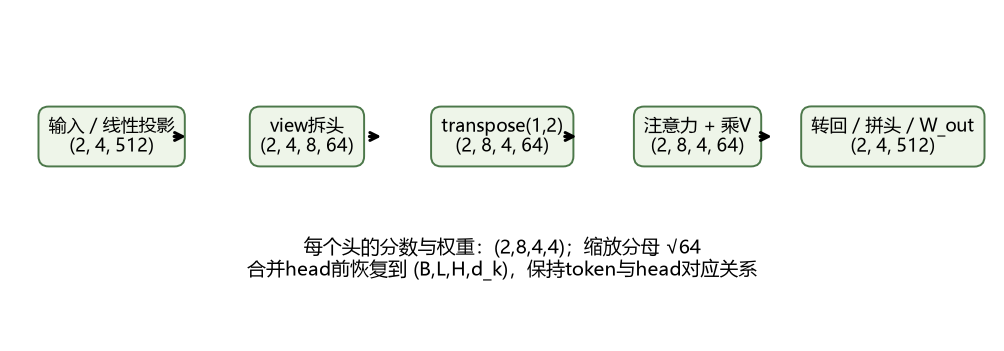

## 13. MultiHeadAttention实现

定义4个独立Linear，分别生成Q/K/V和最终输出。课程采用deepcopy构造4个Linear：参数对象彼此独立，但初始数值相同；本篇逐个构造，初始数值不同，均可训练。不要写成 `[one_linear]*4`，那会重复引用同一层而意外共享参数。

本类只接受**显式4维**allow，广播目标必须是 `(B,H,Lq,Lk)`，避免3维mask发生含义不清的对齐。可以是 `(1,1,Lq,Lk)`、`(B,1,1,Lk)`、`(B,1,Lq,Lk)` 或目标完整形状。

```python
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        if d_model <= 0 or heads <= 0 or d_model % heads:
            raise ValueError('D/H必须为正且D能被H整除')
        self.d_model, self.heads = d_model, heads
        self.d_k = d_model // heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)

    def split_heads(self, tensor):
        b, length, _ = tensor.shape
        return tensor.reshape(b, length, self.heads,
                              self.d_k).transpose(1, 2)

    def forward(self, query, key, value, allow=None):
        if any(t.ndim != 3 or t.shape[-1] != self.d_model
               for t in (query, key, value)):
            raise ValueError('输入必须都是(B,L,D)')
        if not (query.shape[0] == key.shape[0] == value.shape[0]):
            raise ValueError('batch数必须一致')
        if key.shape[1] != value.shape[1]:
            raise ValueError('K/V长度必须一致')
        if allow is not None and allow.ndim != 4:
            raise ValueError('MHA的allow必须显式包含4个轴')
        q = self.split_heads(self.q_proj(query))
        k = self.split_heads(self.k_proj(key))
        v = self.split_heads(self.v_proj(value))
        context, weights, used_weights = scaled_attention(
            q, k, v, allow, dropout=self.attn_dropout)
        merged = context.transpose(1, 2).contiguous().view(
            query.shape[0], query.shape[1], self.d_model)
        return self.out_proj(merged), weights, used_weights

mha = MultiHeadAttention(D, H, dropout=0.1).eval()
output_self, attn_self, used_self = mha(x, x, x, self_allow)
assert output_self.shape == (B, 4, D)
assert attn_self.shape == (B, H, 4, 4)
assert torch.all(attn_self.masked_select(~self_allow.expand_as(attn_self)) == 0)
torch.testing.assert_close(attn_self.sum(-1), torch.ones(B, H, 4))
torch.testing.assert_close(attn_self, used_self)
for bad_d, bad_h in [(15, 4), (16, 0)]:
    try:
        MultiHeadAttention(bad_d, bad_h)
    except ValueError:
        pass
    else:
        raise AssertionError('非法头数/维度应被拒绝')
try:
    mha(x, x, x, torch.ones(B, 4, 4, dtype=torch.bool))
except ValueError:
    pass
else:
    raise AssertionError('本类拒绝含义不明确的3维mask')
print('MHA输出:', tuple(output_self.shape), '| 权重:', tuple(attn_self.shape))
print('掩码概率为0、行和为1、整除和mask维度检查：通过')
```

self-attention的Q/K/V**来源相同**，但经过不同投影后数值通常不同。课件第42页声明dropout却未传给attention，本实现显式传入，训练时才会生效。

本段实测输出：

```text
MHA输出: (3, 4, 16) | 权重: (3, 4, 4, 4)
掩码概率为0、行和为1、整除和mask维度检查：通过
```

## 14. view、transpose、contiguous：同形状不等于同顺序

`view`按当前布局改变形状，`transpose`交换轴；它们即使返回相同shape，也不表示token/head的对应关系相同。多头context先从 `(B,H,L,d_k)` 转成 `(B,L,H,d_k)`，然后才拼特征轴。

```python
probe = torch.arange(2*3*4*2).reshape(2, 3, 4, 2)
transposed = probe.transpose(1, 2)  # (B,L,H,d_k)
assert not transposed.is_contiguous()
merged = transposed.contiguous().view(2, 4, 6)
torch.testing.assert_close(merged, transposed.reshape(2, 4, 6))
assert merged[0, 0].tolist() == [0, 1, 8, 9, 16, 17]
wrong = probe.reshape(2, 4, 6)  # 不转轴直接拼，混淆token/head。
assert not torch.equal(merged, wrong)
print('正确拼头的第1个token:', merged[0, 0].tolist())
print('直接改shape的第1个token:', wrong[0, 0].tolist())
```

不能绝对说“transpose后一定不能view”。是否可view取决于stride与目标shape是否兼容；在这里合并H和d_k通常需要连续布局。`reshape`在兼容时可返回视图，必要时复制；`contiguous()`对已连续的张量也不必再复制。

本段实测输出：

```text
正确拼头的第1个token: [0, 1, 8, 9, 16, 17]
直接改shape的第1个token: [0, 1, 2, 3, 4, 5]
```

## 15. 三种Attention用法与真实mask验证

| 用法 | Q来源 | K/V来源 | allow |
| --- | --- | --- | --- |
| Encoder self-attention | 源序列表示 | 同一源序列 | 源key padding |
| Decoder masked self-attention | 右移后的目标表示 | 同一目标表示 | 目标key padding + causal |
| Cross-attention | decoder表示 | encoder memory | 源key padding；通常不加目标causal |

下面的memory是独立生成的模拟encoder输出，**Lq=4、Lk=5**。检验被屏蔽源位置被改成巨大值后输出不变；再检验目标未来位置被改变时，前面query的causal输出不变。形状检查无法替代这些行为检查。

```python
memory = torch.randn(B, 5, D)
source_valid = torch.tensor([[1,1,1,1,1],
                             [1,1,1,0,0],
                             [1,1,0,0,0]], dtype=torch.bool)
cross_allow = source_valid[:, None, None, :]
with torch.no_grad():
    cross_out, cross_w, _ = mha(x, memory, memory, cross_allow)
    dirty = memory.clone()
    dirty[~source_valid] = 10000
    dirty_out, dirty_w, _ = mha(x, dirty, dirty, cross_allow)
    torch.testing.assert_close(cross_out, dirty_out)
    torch.testing.assert_close(cross_w, dirty_w)
    assert cross_out.shape == (B, 4, D)
    assert cross_w.shape == (B, H, 4, 5)
    assert (cross_w.masked_select(~cross_allow.expand_as(cross_w)) == 0).all()
    future_changed = x.clone()
    future_changed[0, 3] += 100
    changed_out, _, _ = mha(future_changed, future_changed,
                            future_changed, self_allow)
    torch.testing.assert_close(output_self[0, :3], changed_out[0, :3])
    # 双向self-attention则只限制key padding。
    encoder_out, encoder_w, _ = mha(x, x, x, key_allow)
print('Cross输出/权重:', tuple(cross_out.shape), tuple(cross_w.shape))
print('源PAD扰动不影响输出、目标未来扰动不影响过去：通过')
```

本段实测输出：

```text
Cross输出/权重: (3, 4, 16) (3, 4, 4, 5)
源PAD扰动不影响输出、目标未来扰动不影响过去：通过
```

## 16. 与PyTorch官方MultiheadAttention对照

不同API的bool mask语义必须分别核对：

| 接口 | bool True的含义 |
| --- | --- |
| 本篇allow；课件代码中的1 | 允许读取 |
| `nn.MultiheadAttention.attn_mask` | 屏蔽该连接 |
| `nn.MultiheadAttention.key_padding_mask` | 屏蔽该key |
| `F.scaled_dot_product_attention.attn_mask` | 允许读取 |

下面复制相同投影权重，关闭dropout，并用 `batch_first=True` 对齐输入布局，验证self、causal self与cross三种输出和每头概率。`nn.MultiheadAttention`默认返回head平均权重，本篇用 `average_attn_weights=False` 保留head轴。

```python
reference = nn.MultiheadAttention(D, H, dropout=0,
                                  batch_first=True).eval()
with torch.no_grad():
    reference.in_proj_weight.copy_(torch.cat([
        mha.q_proj.weight, mha.k_proj.weight, mha.v_proj.weight]))
    reference.in_proj_bias.copy_(torch.cat([
        mha.q_proj.bias, mha.k_proj.bias, mha.v_proj.bias]))
    reference.out_proj.load_state_dict(mha.out_proj.state_dict())

comparison = {}
for name, q, k, v, allow, pad_block, attn_block in [
    ('encoder self', x, x, x, key_allow, ids == PAD, None),
    ('causal self', x, x, x, self_allow, ids == PAD, ~causal[0,0]),
    ('cross', x, memory, memory, cross_allow, ~source_valid, None)]:
    with torch.no_grad():
        ours, ours_w, _ = mha(q, k, v, allow)
        theirs, theirs_w = reference(q, k, v, attn_mask=attn_block,
            key_padding_mask=pad_block, need_weights=True,
            average_attn_weights=False)
    torch.testing.assert_close(ours, theirs, rtol=1e-5, atol=1e-6)
    torch.testing.assert_close(ours_w, theirs_w, rtol=1e-5, atol=1e-6)
    comparison[name] = float((ours - theirs).abs().max())
    print(name, '| 最大输出误差:', f'{comparison[name]:.2e}')
```

该检查能发现投影顺序、缩放分母、转置、拼头和mask方向的错误。SDPA另有函数式 `dropout_p`，不会因外层module执行 `.eval()`而自动清零；使用它时应写 `dropout_p=p if self.training else 0.0`。本篇使用 `nn.Dropout`，其train/eval行为由模块管理。

本段实测输出：

```text
encoder self | 最大输出误差: 2.38e-07
causal self | 最大输出误差: 2.38e-07
cross | 最大输出误差: 0.00e+00
```

## 17. 每个head的注意力热力图

展示第2句的cross-attention：行=query位置，列=源key位置，最后两列PAD权重为0。这里模型尚未学习语言任务，query/key只是示例特征，所以图用于检查mask与概率，不用于推断真实翻译对齐。

```python
head_maps = cross_w[1].detach().numpy()
fig, axes = plt.subplots(1, H, figsize=(10, 2.9), layout='constrained')
upper = float(head_maps.max())
for head, ax in enumerate(axes):
    im = ax.imshow(head_maps[head], cmap='YlGnBu', vmin=0,
                   vmax=upper, aspect='auto')
    ax.set(xticks=range(5), yticks=range(4), title=f'Head {head+1}',
           xlabel='key列')
    ax.set_xticklabels(['s0','s1','s2','PAD','PAD'], rotation=45,
                        ha='right', fontsize=8)
    if head == 0:
        ax.set_ylabel('query行')
fig.colorbar(im, ax=axes, label='softmax概率', shrink=0.85)
plt.show()
print('第2句所有head的PAD列最大概率:', float(cross_w[1, :, :, 3:].max()))
```

PAD query行仍有概率分布；实际评估时可只绘制有效query，避免把这些行当成有效生成结果。这里保留全部4行，以便对照mask机制。

本段实测输出：

```text
第2句所有head的PAD列最大概率: 0.0
```

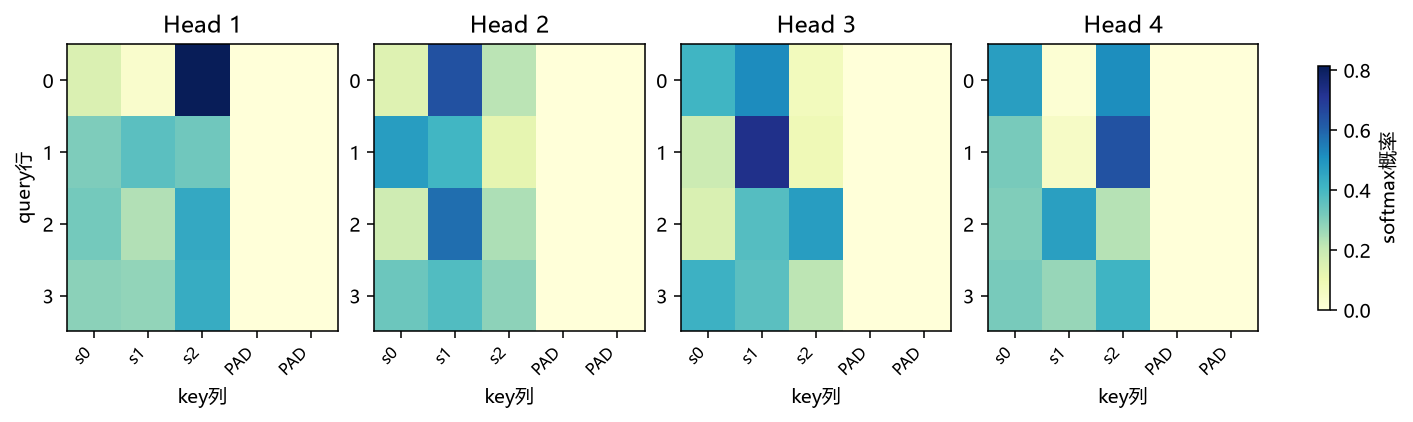

## 18. PositionwiseFeedForward：逐位置的非线性变换

$$FFN(x)=\operatorname{ReLU}(xW_1+b_1)W_2+b_2$$

带dropout的课程流程为 `Linear(D,d_ff) → ReLU → Dropout → Linear(d_ff,D)`。第一层扩展或改变特征空间，非线性增强表达能力，第二层恢复D以便后续残差连接。`d_ff`常取更大的值，但不是序列长度，也没有必须为4D的接口要求；课件第50页用512→1024→512，本篇用16→32→16。

**逐位置**表示同一组参数用于每个token，只在最后特征轴变换，不在位置之间传信息。Attention负责聚合不同位置，FFN负责加工每个位置的特征，两者作用互补。

```python
class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.w2(self.dropout(F.relu(self.w1(x))))

ffn = PositionwiseFeedForward(D, 32, dropout=0.1).eval()
with torch.no_grad():
    ffn_out = ffn(output_self)
    changed_tokens = output_self.clone()
    changed_tokens[:, 2] += 100
    changed_ffn = ffn(changed_tokens)
    torch.testing.assert_close(ffn_out[:, [0,1,3]],
                               changed_ffn[:, [0,1,3]])
    per_token = torch.stack([ffn(output_self[:, t]) for t in range(4)], dim=1)
    torch.testing.assert_close(ffn_out, per_token)
assert ffn_out.shape == (B, 4, D)
print('FFN:', tuple(output_self.shape), '→', tuple(ffn_out.shape))
print('改一个token不影响其他位置、逐位置计算一致：通过')
```

现代模型还可能用GELU、SwiGLU等前馈结构，本篇按day08的ReLU双线性层实现。测试位置独立性时要用eval关闭dropout，否则随机mask差异会干扰比较。

本段实测输出：

```text
FFN: (3, 4, 16) → (3, 4, 16)
改一个token不影响其他位置、逐位置计算一致：通过
```

## 19. 把组件接通：前向、loss与反向传播

下面是一条教学用的 **源/目标输入 → masked self-attention → cross-attention → FFN → 词表logits** 计算链。源表示直接由embedding+PE提供，尚未经过encoder层；链中也尚未加入残差和LayerNorm，因此不把它称为完整Transformer。

用一个右移目标batch检查shape、PAD loss、梯度和一次参数更新。标签1=SOS、2=EOS、0=PAD，其余是模拟词表ID；源和目标各有独立embedding。只验证训练接口接通，不报告语言质量或收敛结论。

```python
class ComponentDemo(nn.Module):
    def __init__(self, vocab_size=20):
        super().__init__()
        self.src_embed = Embeddings(vocab_size, D, PAD)
        self.tgt_embed = Embeddings(vocab_size, D, PAD)
        self.src_pos = PositionalEncoding(D, 0.1, 32)
        self.tgt_pos = PositionalEncoding(D, 0.1, 32)
        self.self_attn = MultiHeadAttention(D, H, 0.1)
        self.cross_attn = MultiHeadAttention(D, H, 0.1)
        self.ffn = PositionwiseFeedForward(D, 32, 0.1)
        self.generator = nn.Linear(D, vocab_size)

    def forward(self, source, target_input):
        memory = self.src_pos(self.src_embed(source))
        target = self.tgt_pos(self.tgt_embed(target_input))
        target_allow = ((target_input != PAD)[:, None, None, :]
                        & causal_allow(target_input.shape[1], target.device))
        target, _, _ = self.self_attn(target, target, target, target_allow)
        target, _, _ = self.cross_attn(target, memory, memory,
                                     (source != PAD)[:, None, None, :])
        return self.generator(self.ffn(target))

source_ids = torch.tensor([[4,5,6,2,0], [7,8,2,0,0], [9,2,0,0,0]])
labels = torch.tensor([[10,11,12,2], [13,14,2,0], [15,2,0,0]])
target_input = torch.cat([torch.full((B,1), 1), labels[:, :-1]], dim=1)
demo = ComponentDemo().train()
optim = torch.optim.Adam(demo.parameters(), lr=0.001)
before = demo.self_attn.q_proj.weight.detach().clone()
optim.zero_grad()
logits = demo(source_ids, target_input)
assert logits.shape == (B, 4, 20)
loss = F.cross_entropy(logits.reshape(-1, 20), labels.reshape(-1),
                       ignore_index=PAD)
valid_labels = labels != PAD
torch.testing.assert_close(loss,
    F.cross_entropy(logits[valid_labels], labels[valid_labels]))
loss.backward()
grad_norms = {}
for name, module in [('src_embed', demo.src_embed),
                     ('tgt_embed', demo.tgt_embed),
                     ('self_attn', demo.self_attn),
                     ('cross_attn', demo.cross_attn),
                     ('ffn', demo.ffn), ('generator', demo.generator)]:
    gradients = [p.grad for p in module.parameters()]
    assert all(g is not None and torch.isfinite(g).all() for g in gradients)
    grad_norms[name] = sum(float(g.square().sum()) for g in gradients) ** 0.5
    assert grad_norms[name] > 0
for emb in [demo.src_embed, demo.tgt_embed]:
    assert torch.all(emb.lut.weight.grad[PAD] == 0)
optim.step()
assert not torch.equal(before, demo.self_attn.q_proj.weight)
print('右移输入：\n', target_input)
print('logits:', tuple(logits.shape), '| 有效标签:', int(valid_labels.sum()))
print('单批loss:', f'{float(loss.detach()):.6f}')
print('各模块梯度范数:', {k:round(v, 6) for k,v in grad_norms.items()})
print('PAD loss排除、PAD embedding梯度为0、参数更新：通过')
```

`CrossEntropyLoss`直接接收logits，内部做log_softmax；不要先softmax再传进去。这里只有一次更新，loss数值用于验证计算链，不能证明模型学会了翻译。完整训练仍需数据划分、encoder/decoder堆叠、残差/LayerNorm、优化计划、推理循环与独立评估。

本段实测输出：

```text
右移输入：
 tensor([[ 1, 10, 11, 12],
        [ 1, 13, 14,  2],
        [ 1, 15,  2,  0]])
logits: (3, 4, 20) | 有效标签: 9
单批loss: 2.937707
各模块梯度范数: {'src_embed': 0.073786, 'tgt_embed': 0.078294, 'self_attn': 0.659136, 'cross_attn': 0.794621, 'ffn': 0.605674, 'generator': 0.485963}
PAD loss排除、PAD embedding梯度为0、参数更新：通过
```

## 20. 常见错误与课件核对

| 容易出错的点 | 正确理解与处理 |
| --- | --- |
| Embedding输入被叫成“词向量” | 输入是整数ID，查表后才是向量；0≤id<V |
| 把位置编码当可训练Parameter | 本篇固定PE是buffer；只有后续参数学习如何使用它 |
| 奇数D时cos赋值失败 | 余弦列较少，按列数裁剪angles |
| True/1到底是可见还是屏蔽 | 查看具体实现；本篇True=允许，MHA官方bool mask True=屏蔽 |
| 右移输入后仍遮对角线 | 对角线是当前历史输入，应保留；只遮未来 |
| 用零embedding代替PAD mask | PE、bias和softmax会让PAD参与运算，仍需key mask和loss mask |
| 全0mask测试只看输出shape | `−1e9`会产生均匀概率；全屏蔽行须明确定义处理 |
| 直接把 `(B,L,L)` 广播到多头 | 使用 `(B,1,L,L)`，或按接口要求显式转换 |
| 256/8得到64 | 正确是32；512/8才是64 |
| 直接reshape代替head/token轴转置 | 先transpose到正确轴顺序，再合并H与d_k |
| 声明dropout但没有调用 | attention调用显式传入；eval时关闭 |
| 注意力dropout后仍要求行和1 | 对原softmax概率检查行和；dropout后的used_weights可能不为1 |
| FFN能读取其他token | 它只处理最后特征轴；位置间信息由attention聚合 |

对应课件的具体位置：第33、45页的文字mask约定与第35—36页代码相反，本文采用代码中的“1可见”；第34页注释写`nn.triu`，实际调用的是`np.triu`；第40、47页有每头维数笔误；第42页未把声明的dropout传入attention；第43页使用全零mask，结合`masked_fill(mask==0,-1e9)`会产生均匀概率；第44页关于transpose后必须contiguous的表述过于绝对。笔记保留课程主题，并在独立示例中澄清这些问题。

## 21. 复习题与答案

1. **词表V=1000，ID=1000合法吗？** 不合法。最大ID是999，词表大小不是最大索引。
2. **PE相加后shape变了吗？** 不变，仍是 `(B,L,D)`；PE的batch轴为1，通过广播加到各句。
3. **为何PE用register_buffer？** 固定编码随模型迁移并保存，但不作为可训练参数。
4. **causal mask为什么保留对角线？** 目标输入已经右移，对角线包含当前已知历史token，标签在下一token。
5. **Q为 `(3,4,4,4)`，K为 `(3,4,5,4)`，权重是什么shape？** `(3,4,4,5)`，按 `(B,H,Lq,Lk)` 理解。
6. **cross-attention输出长度是源长度还是目标长度？** 由Q决定，这里是目标query长度4。
7. **D=256，H=8，每头多少维？** 32维；缩放分母为√32。
8. **softmax前整行都填−1e9能让概率全0吗？** 不能，结果均匀；填−∞则常规softmax出现NaN。本篇拒绝该行。
9. **官方MHA的bool True与本篇allow的True相同吗？** 相反。本篇True可见，官方MHA True屏蔽；SDPA的bool True可见。
10. **把FFN第2个token输入改掉，其他token会变吗？** eval且关闭随机dropout影响时不会，因为FFN逐位置共享参数。
11. **多头一定越多越好吗？** 不是。固定D时头越多每头维度越小，效果需结合任务、预算与验证集判断。
12. **本篇一次loss与参数更新证明了什么？** 证明基础组件的前向与反向接口可接通，不证明完整Transformer训练收敛或具备翻译质量。

## 22. day08资料索引与实测记录

来源：[NLP自然语言处理网盘资料](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。课程路径为 `2026最新版NLP自然语言处理`；课件位于 `01-课件/08-Tranformer架构和实现.pdf`，本篇阅读第21—50页；当天视频位于 `03-视频/day08`。

| 视频 | 原文件主题 | 本篇对应 |
| --- | --- | --- |
| 01 | 学习Transformer架构的路线 | 第1节 |
| 02 | 词嵌入层代码实现 | 第3节 |
| 03 | 位置编码层原理介绍 | 第4节 |
| 04 | 位置编码总结 | 第4—5节 |
| 05 | 位置编码层代码实现 | 第5节 |
| 06 | 位置编码层代码测试 | 第5—6节 |
| 07 | 扩展：上三角矩阵演示 | 第7节 |
| 08 | 扩展：下三角矩阵演示 | 第7节 |
| 09 | 扩展：掩码张量可视化 | 第8节 |
| 10 | 扩展：masked_fill()函数介绍 | 第9—10节 |
| 11 | 注意力机制代码实现及测试 | 第9—11节 |
| 12 | 多头注意力原理图（上） | 第12节 |
| 13 | 多头注意力原理图（下） | 第12节 |
| 14 | 多头注意力代码实现 | 第13节 |
| 15 | 多头注意力代码测试 | 第14—17节 |
| 16 | 前馈全连接层代码实现及测试 | 第18节 |

第15—16、19节是为理解与验收增加的独立示例：包含变长cross-attention、PAD/未来扰动检查、官方MHA数值对照及单批梯度检查，不声称是课程原始实现或视频逐字记录。

本篇所有Python段按顺序实际执行；检查通过：ID与embedding形状、位置编码buffer/offset/奇数维、causal与padding组合、全屏蔽行拒绝、概率行和与屏蔽概率、dropout train/eval、head拆拼、self/cross与官方MHA数值一致、FFN位置独立性、有效标签loss、各模块有限非零梯度和一次参数更新。图片均为本篇示意图或代码实际绘图，存于Notebook内部。